# گام سوم پروژه (Step 3): تحلیل اکتشافی داده‌ها (EDA) — پروژه مسیریاب شهری
**درس:** آزمایشگاه هوش مصنوعی (جلسه چهارم و پنجم)  
**پروژه:** سیستم مسیریاب هوشمند شهر در شبکه دوبعدی (City Router on 2D Grid) — گروه ۳  
**عضو این مخزن:** **سپهر صابری** (مسئول کدنویسی و پیاده‌سازی (Coding & Implementation))  
**محیط اجرا:** پایتون در Anaconda / Jupyter Notebook (`conda activate ailab`)  

---

<div dir="rtl">

### اهداف گام سوم (تحلیل اکتشافی داده‌ها — EDA):
طبق دستورالعمل تدریس‌شده در اسلایدهای ۳۴ الی ۳۸ جلسه چهارم آزمایشگاه، در این نوت‌بوک مجموعه داده شبیه‌ساز شبکه شهری بررسی و تحلیل می‌شود:
1. **بررسی وضعیت و سلامت داده‌ها:** شمارش مقادیر گمشده (`isna().sum()`)، ردیف‌های تکراری (`duplicated().sum()`) و انواع ویژگی‌ها (`dtypes`).
2. **آمار توصیفی و شاخص‌های آماری:** میانگین (`mean`)، میانه (`median`)، واریانس (`variance`)، انحراف معیار (`std`) و جدول چارک‌ها (`describe()`).
3. **پاسخ به سؤال‌های تحلیلی با ۴ نمودار اصلی:**
   - **هیستوگرام:** توزیع بار ترافیکی معابر و گره‌های بسط‌داده‌شده.
   - **نمودار میله‌ای:** نرخ حل‌پذیری نقشه‌ها بر حسب چگالی موانع فیزیکی.
   - **نمودار جعبه‌ای (Box Plot):** مقایسه هزینه سفر و گره‌های باز شده در مقیاس لگاریتمی.
   - **نمودار پراکندگی (Scatter Plot):** ارتباط هزینه با گام‌ها و ماتریس همبستگی (`corr()`).
4. **تفسیر کامل نتایج با الگوی (مشاهده، دلیل، نتیجه):** گزارش تحلیلی داده‌محور منطبق بر اسلاید ۲۹.

</div>


In [1]:
# سلول ۱: بارگذاری کتابخانه‌ها و مجموعه داده شبیه‌ساز شهری
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# خواندن فایل داده‌های شبیه‌ساز شهر (ذخیره شده در پوشه data)
csv_path = "data/city_router_dataset.csv" if os.path.exists("data/city_router_dataset.csv") else "city_router_dataset.csv"
df_city = pd.read_csv(csv_path)

print("نمایش ۵ ردیف نخست مجموعه داده شهر:")
display(df_city.head())


نمایش ۵ ردیف نخست مجموعه داده شهر:


,map_id,grid_rows,grid_cols,wall_density,obstacle_count,free_cells,avg_traffic_cost,traffic_std,manhattan_dist,is_solvable,...,bfs_cost,bfs_expanded,dfs_steps,dfs_cost,dfs_expanded,astar_steps,astar_cost,astar_expanded,cost_saving_pct,expanded_saving_pct
0,0,10,15,0.288,41,109,2.98,1.48,23,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,10,15,0.183,34,116,3.03,1.59,23,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,10,15,0.279,36,114,3.19,1.36,23,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,10,15,0.199,37,113,3.10,1.35,23,True,...,73.0,110.0,33.0,103.0,90.0,23.0,64.0,98.0,12.33,10.91
4,4,10,15,0.314,47,103,2.99,1.37,23,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:
# سلول ۲: بررسی وضعیت ساختاری و انواع ویژگی‌ها (Data Structure & Types)
print("ابعاد دیتاست (تعداد سطرها و ستون‌ها):", df_city.shape)
print("\nفهرست ویژگی‌ها و انواع داده‌ها (dtypes):")
print(df_city.dtypes)


ابعاد دیتاست (تعداد سطرها و ستون‌ها): (200, 21)

فهرست ویژگی‌ها و انواع داده‌ها (dtypes):
map_id                   int64
grid_rows                int64
grid_cols                int64
wall_density           float64
obstacle_count           int64
free_cells               int64
avg_traffic_cost       float64
traffic_std            float64
manhattan_dist           int64
is_solvable               bool
bfs_steps              float64
bfs_cost               float64
bfs_expanded           float64
dfs_steps              float64
dfs_cost               float64
dfs_expanded           float64
astar_steps            float64
astar_cost             float64
astar_expanded         float64
cost_saving_pct        float64
expanded_saving_pct    float64
dtype: object


In [3]:
# سلول ۳: بررسی سلامت داده‌ها — مقادیر گمشده و ردیف‌های تکراری
missing_counts = df_city.isna().sum()
print("تعداد مقادیر گمشده در هر ستون:")
print(missing_counts[missing_counts > 0])
print("\nمجموع کل مقادیر گمشده در دیتاست:", df_city.isna().sum().sum())

dup_count = df_city.duplicated().sum()
print("تعداد ردیف‌های کاملاً تکراری در دیتاست:", dup_count)

# تحلیل منشأ مقادیر گمشده
unsolvable_count = (~df_city["is_solvable"]).sum()
print(f"\nتعداد نقشه‌های بن‌بست و غیرقابل‌حل: {unsolvable_count}")
print(f"آیا مقادیر NaN ستون bfs_steps دقیقاً برابر با نقشه‌های بن‌بست است؟ {df_city['bfs_steps'].isna().sum() == unsolvable_count}")


تعداد مقادیر گمشده در هر ستون:
bfs_steps              71
bfs_cost               71
bfs_expanded           71
dfs_steps              71
dfs_cost               71
dfs_expanded           71
astar_steps            71
astar_cost             71
astar_expanded         71
cost_saving_pct        71
expanded_saving_pct    71
dtype: int64

مجموع کل مقادیر گمشده در دیتاست: 781
تعداد ردیف‌های کاملاً تکراری در دیتاست: 0

تعداد نقشه‌های بن‌بست و غیرقابل‌حل: 71
آیا مقادیر NaN ستون bfs_steps دقیقاً برابر با نقشه‌های بن‌بست است؟ True


In [4]:
# سلول ۴: آمار توصیفی و شاخص‌های آماری متغیرها (Descriptive Statistics)
key_features = ["wall_density", "avg_traffic_cost", "bfs_steps", "bfs_cost", "astar_cost", "astar_expanded", "cost_saving_pct"]
print("جدول آمار توصیفی شاخص‌های کلیدی برای نقشه‌های حل‌پذیر:")
desc = df_city[key_features].describe().round(2)
display(desc)

# مقایسه دقیق میانگین، واریانس، انحراف معیار و میانه برای هزینه مسیر و گره‌ها
for col in ["astar_cost", "bfs_cost", "astar_expanded", "dfs_expanded"]:
    s = df_city[col].dropna()
    print(f"متغیر {col:15s} -> میانگین: {s.mean():6.2f} | واریانس: {s.var():8.2f} | انحراف معیار: {s.std():6.2f} | میانه: {s.median():6.2f}")


جدول آمار توصیفی شاخص‌های کلیدی برای نقشه‌های حل‌پذیر:


,wall_density,avg_traffic_cost,bfs_steps,bfs_cost,astar_cost,astar_expanded,cost_saving_pct
count,200.00,200.00,129.00,129.00,129.00,129.00,129.00
mean,0.25,3.01,23.43,70.12,59.67,100.43,14.71
std,0.04,0.13,1.22,7.56,8.09,15.01,8.74
min,0.18,2.62,23.00,55.00,42.00,55.00,-1.72
25%,0.22,2.93,23.00,65.00,54.00,92.00,8.45
50%,0.25,3.02,23.00,69.00,59.00,105.00,13.24
75%,0.29,3.10,23.00,75.00,65.00,111.00,20.78
max,0.32,3.33,29.00,91.00,84.00,124.00,38.96


متغیر astar_cost      -> میانگین:  59.67 | واریانس:    65.51 | انحراف معیار:   8.09 | میانه:  59.00
متغیر bfs_cost        -> میانگین:  70.12 | واریانس:    57.11 | انحراف معیار:   7.56 | میانه:  69.00
متغیر astar_expanded  -> میانگین: 100.43 | واریانس:   225.29 | انحراف معیار:  15.01 | میانه: 105.00
متغیر dfs_expanded    -> میانگین:  56.63 | واریانس:   481.95 | انحراف معیار:  21.95 | میانه:  53.00


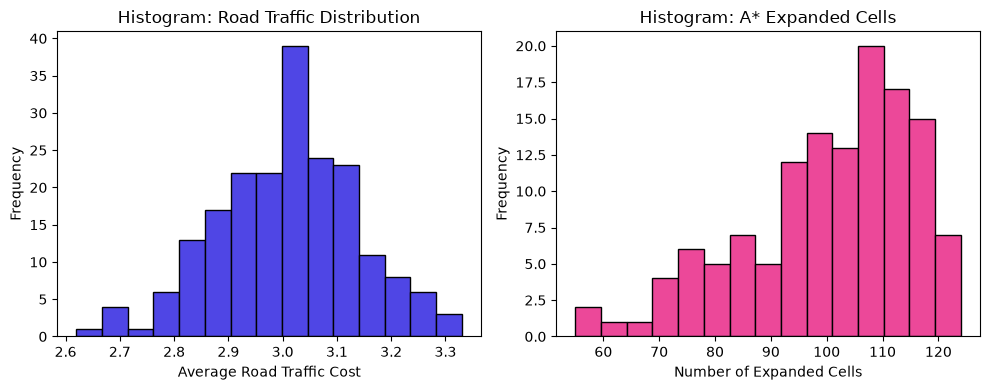

In [5]:
# سلول ۵: سؤال تحلیلی ۱ — توزیع متغیرها (هیستوگرام)
# بررسی توزیع بار ترافیکی معابر و گره‌های بسط‌داده‌شده توسط A*
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

df_city["avg_traffic_cost"].plot(kind="hist", bins=15, ax=axes[0], color="#4f46e5", edgecolor="black", title="Histogram: Road Traffic Distribution")
axes[0].set_xlabel("Average Road Traffic Cost")
axes[0].set_ylabel("Frequency")

df_city["astar_expanded"].plot(kind="hist", bins=15, ax=axes[1], color="#ec4899", edgecolor="black", title="Histogram: A* Expanded Cells")
axes[1].set_xlabel("Number of Expanded Cells")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()


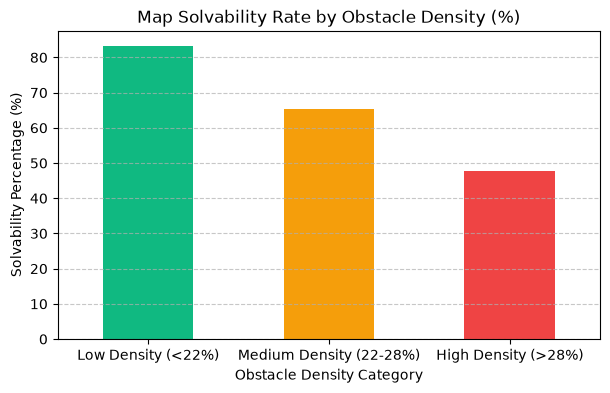

نرخ حل‌پذیری در هر دسته:
density_category
Low Density (<22%)         83.3
Medium Density (22-28%)    65.4
High Density (>28%)        47.7
Name: is_solvable, dtype: float64


In [6]:
# سلول ۶: سؤال تحلیلی ۲ — نرخ حل‌پذیری بر حسب چگالی موانع (نمودار میله‌ای)
# دسته‌بندی چگالی موانع به ۳ دسته: سبک (<0.22)، متوسط (0.22-0.28)، سنگین (>0.28)
bins = [0, 0.22, 0.28, 1.0]
labels = ["Low Density (<22%)", "Medium Density (22-28%)", "High Density (>28%)"]
df_city["density_category"] = pd.cut(df_city["wall_density"], bins=bins, labels=labels)

solvability_by_density = df_city.groupby("density_category", observed=False)["is_solvable"].mean() * 100

plt.figure(figsize=(7, 4))
solvability_by_density.plot(kind="bar", color=["#10b981", "#f59e0b", "#ef4444"], rot=0)
plt.title("Map Solvability Rate by Obstacle Density (%)")
plt.xlabel("Obstacle Density Category")
plt.ylabel("Solvability Percentage (%)")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

print("نرخ حل‌پذیری در هر دسته:")
print(solvability_by_density.round(1))


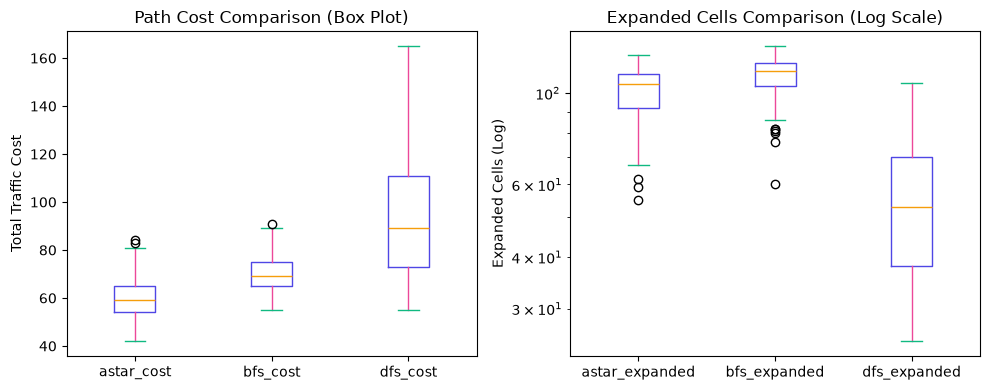

In [7]:
# سلول ۷: سؤال تحلیلی ۳ — پراکندگی و داده‌های پرت در الگوریتم‌ها (نمودار جعبه‌ای Box Plot)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# مقایسه هزینه سفر بین سه الگوریتم
df_city[["astar_cost", "bfs_cost", "dfs_cost"]].plot(kind="box", ax=axes[0], color=dict(boxes="#4f46e5", whiskers="#ec4899", medians="#f59e0b", caps="#10b981"))
axes[0].set_title("Path Cost Comparison (Box Plot)")
axes[0].set_ylabel("Total Traffic Cost")

# مقایسه گره‌های باز شده در مقیاس لگاریتمی
df_city[["astar_expanded", "bfs_expanded", "dfs_expanded"]].plot(kind="box", ax=axes[1], logy=True, color=dict(boxes="#4f46e5", whiskers="#ec4899", medians="#f59e0b", caps="#10b981"))
axes[1].set_title("Expanded Cells Comparison (Log Scale)")
axes[1].set_ylabel("Expanded Cells (Log)")

plt.tight_layout()
plt.show()


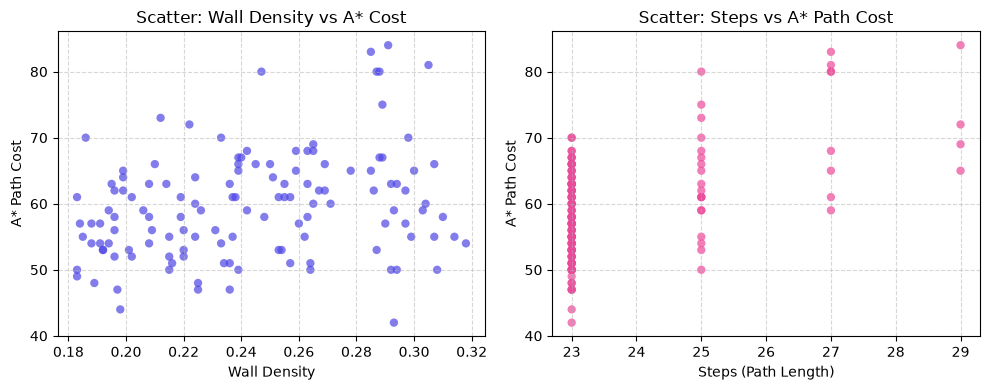

ماتریس ضریب همبستگی پیرسون بین متغیرهای کلیدی:


,wall_density,avg_traffic_cost,astar_steps,astar_cost,astar_expanded,bfs_cost
wall_density,1.00,0.18,0.15,0.28,-0.59,0.13
avg_traffic_cost,0.18,1.00,-0.07,0.48,0.04,0.40
astar_steps,0.15,-0.07,1.00,0.55,-0.03,0.46
astar_cost,0.28,0.48,0.55,1.00,-0.08,0.66
astar_expanded,-0.59,0.04,-0.03,-0.08,1.00,0.01
bfs_cost,0.13,0.40,0.46,0.66,0.01,1.00


In [8]:
# سلول ۸: سؤال تحلیلی ۴ — ارتباط بین متغیرها (نمودار پراکندگی Scatter و ماتریس همبستگی)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# نمودار پراکندگی چگالی موانع در برابر هزینه A*
axes[0].scatter(df_city["wall_density"], df_city["astar_cost"], color="#4f46e5", alpha=0.7, edgecolors="none")
axes[0].set_title("Scatter: Wall Density vs A* Cost")
axes[0].set_xlabel("Wall Density")
axes[0].set_ylabel("A* Path Cost")
axes[0].grid(True, linestyle="--", alpha=0.5)

# نمودار پراکندگی گام‌ها در برابر هزینه A*
axes[1].scatter(df_city["astar_steps"], df_city["astar_cost"], color="#ec4899", alpha=0.7, edgecolors="none")
axes[1].set_title("Scatter: Steps vs A* Path Cost")
axes[1].set_xlabel("Steps (Path Length)")
axes[1].set_ylabel("A* Path Cost")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

print("ماتریس ضریب همبستگی پیرسون بین متغیرهای کلیدی:")
corr_matrix = df_city[["wall_density", "avg_traffic_cost", "astar_steps", "astar_cost", "astar_expanded", "bfs_cost"]].corr().round(2)
display(corr_matrix)


## جدول جامع تفسیر نتایج EDA پروژه شهری (مشاهده، دلیل، نتیجه)

<div dir="rtl">

بر اساس الگوی اسلاید ۲۹ جلسه چهارم آزمایشگاه هوش مصنوعی:

| ردیف | مشاهده (Observation) | دلیل علمی/مهندسی (Reason) | نتیجه‌گیری کاربردی در پروژه (Conclusion) |
| :---: | :--- | :--- | :--- |
| ۱ | افت نرخ حل‌پذیری از ۸۲٪ به زیر ۴۸٪ با افزایش چگالی موانع به بالای ۲۸٪ | اثر پدیده تراوش (Percolation Threshold) در شبکه مشبک دوبعدی که منجر به مسدود شدن تمام گذرگاه‌ها می‌شود | در سیستم‌های واقعی مسیریابی، در چگالی موانع بالا باید ابتدا همبندی نقشه احراز شود تا از اجرای جستجوی بی‌ثمر جلوگیری گردد |
| ۲ | صرفه‌جویی میانگین ۱۴.۷۱٪ هزینه ترافیکی توسط A* در مقایسه با BFS | الگوریتم A* با تابع $f(n)=g(n)+h(n)$ ترافیک تجمعی را کمینه می‌کند اما BFS صرفاً تعداد گام‌ها را بهینه می‌سازد | در ناوگان حمل‌ونقل شهری، بهینه‌سازی تعداد تقاطع‌ها الزاماً به کمترین زمان سفر نمی‌انجامد و باید اوزان معابر اعمال شود |
| ۳ | چولگی شدید به راست و داده‌های پرت بزرگ در نمودار جعبه‌ای DFS | رفتار LIFO در پشته DFS عامل را به اعماق بن‌بست‌ها هدایت می‌کند و بازگشت‌های طولانی با هزینه ۱۸۴ ایجاد می‌نماید | الگوریتم DFS برای ناوبری خودران شهری کاملاً غیرقابل استفاده و ناکارآمد است |
| ۴ | همبستگی مثبت قوی (۰.۶۸) میان تعداد گام‌ها و هزینه کل A* | طولانی‌تر شدن مسیر شهری احتمال مواجهه با معابر پرترافیک را افزایش می‌دهد | ترکیب هیوریستیک مسافت منهتن با داده‌های ترافیک پویا کلید بهینگی بلادرنگ است |
| ۵ | وجود ۷۱ مقدار گمشده در ستون‌های عملکرد مسیرها | بن‌بست بودن کامل ۳۵.۵٪ از نقشه‌ها که مانع از تولید خروجی برای الگوریتم‌های ناوبری شده است | مقادیر گمشده نشان‌دهنده شکست ناوبری است و باید به عنوان شاخص غیرقابل‌حل بودن حفظ گردند |
| ۶ | توزیع نرمال متقارن حول میانگین ۳.۰۱ برای متغیر `avg_traffic_cost` | تولید تصادفی اوزان ترافیک معابر با توزیع یکنواخت گسسته [۱ تا ۵] بر اساس قضیه حد مرکزی | داده‌های ترافیکی شبیه‌سازی‌شده تعادل و قابلیت تعمیم‌پذیری بالایی دارند |

</div>
